In [2]:
import pandas as pd
import numpy as np

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
os.listdir("/content/drive/MyDrive/Colab Notebooks/output/statistics/")

['sampled_all_systems.csv',
 'concat_flaml.csv',
 'concat_ag.csv',
 'result_monotonic_llama.csv',
 'result_monotonic_mistral.csv',
 'llama.csv',
 'mistral.csv',
 'result_equal_monotonic_ag_equal.csv',
 'result_monotonic_ag_equal.csv',
 'result_equal_monotonic_flaml_equal.csv',
 'result_monotonic_flaml_equal.csv',
 'result_equal_monotonic_rf_equal.csv',
 'result_monotonic_rf_equal.csv',
 'old_concat_rf.csv',
 'old_hpo_all_systems.csv',
 'concat_rf.csv',
 'hpo_all_systems.csv']

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_ag.csv",
    sep=";"
)

adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["predicted_dataset"]
aug_mask = automl_concat_df["trained_dataset"] == automl_concat_df["predicted_dataset"]


automl_concat_df.loc[adapt_mask & (~aug_mask), "Predicted Dataset"] = "Equivalent"
automl_concat_df.loc[(~adapt_mask) & (~aug_mask), "Predicted Dataset"] = "Distinct"
automl_concat_df = automl_concat_df.dropna(subset=["Predicted Dataset"])
automl_concat_df = automl_concat_df.sort_values(by="predicted_dataset")
automl_concat_df

,trained_dataset,predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,Predicted Dataset
0,ed_03,ed_01,ed_01,AutoGluon,gmm_random,25,"['surprise', 'disgust', 'anger']","['admiration', 'disappointment', 'neutral', 'g...",False,0.307054,0.132780,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['admiration', 'sadness', 'joy', 'disappointme...",Equivalent
3,ed_03,ed_01,ed_01,AutoGluon,gmm_random,50,['anger'],"['curiosity', 'admiration', 'remorse', 'neutral']",False,0.307054,0.302905,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['curiosity', 'admiration', 'sadness', 'joy', ...",Equivalent
15,ed_03,ed_01,ed_02,AutoGluon,gmm_random,75,"['surprise', 'fear', 'disgust']","['curiosity', 'admiration', 'neutral', 'optimi...",False,0.307054,0.037344,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['curiosity', 'admiration', 'sadness', 'joy', ...",Distinct
6,ed_03,ed_01,ed_01,AutoGluon,gmm_random,75,[],"['neutral', 'admiration', 'remorse']",False,0.307054,0.294606,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['admiration', 'sadness', 'joy', 'surprise', '...",Equivalent
12,ed_03,ed_01,ed_02,AutoGluon,gmm_random,50,"['surprise', 'fear', 'disgust']","['relief', 'nervousness', 'admiration', 'curio...",False,0.307054,0.020747,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['relief', 'nervousness', 'admiration', 'curio...",Distinct
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1953,ua_05,ua_06,ua_04,AutoGluon,gmm_random,25,[],[],False,0.442095,0.477554,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']",Distinct
1694,ua_01,ua_06,ua_05,AutoGluon,gmm_random,75,"['5', '7']",[],False,0.442095,0.465680,"['3', '5', '10', '1', '7']","['3', '10', '1']",Distinct
1859,ua_03,ua_06,ua_06,AutoGluon,gmm_random,75,[],[],False,0.442095,0.598406,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']",Equivalent
1864,ua_04,ua_06,ua_01,AutoGluon,gmm_random,25,['3'],[],False,0.442095,0.446975,"['3', '5', '10', '1', '7']","['7', '5', '10', '1']",Distinct


In [7]:
automl_concat_df.groupby(["predicted_dataset", "Predicted Dataset"]).size()

predicted_dataset  Predicted Dataset
ed_01              Distinct               3
                   Equivalent             3
ed_02              Distinct               3
                   Equivalent             3
fn_02              Distinct              12
                   Equivalent            15
fn_05              Equivalent             3
fn_06              Distinct              12
                   Equivalent            15
fn_07              Equivalent             3
fn_09              Equivalent             3
fn_10              Equivalent             3
hs_01              Equivalent             3
hs_02              Distinct               6
                   Equivalent             9
hs_03              Distinct              45
                   Equivalent            12
hs_04              Equivalent             3
hs_06              Distinct              48
                   Equivalent            12
hs_08              Distinct              48
                   Equivalent            12
hs_09              Distinct              45
                   Equivalent            12
hs_10              Distinct              45
                   Equivalent            12
hs_11              Equivalent             3
hs_12              Distinct              45
                   Equivalent            12
hs_13              Distinct               6
                   Equivalent             9
hs_14              Equivalent             3
pc_01              Distinct             111
                   Equivalent            24
pc_02              Distinct             111
                   Equivalent            24
pc_03              Distinct             111
                   Equivalent            24
pc_04              Distinct             111
                   Equivalent            24
pc_05              Distinct              57
                   Equivalent             9
pc_06              Distinct             111
                   Equivalent            24
pc_07              Distinct              57
                   Equivalent             9
pc_08              Distinct              57
                   Equivalent             9
sd_03              Equivalent             3
sd_04              Equivalent             3
ua_01              Distinct              48
                   Equivalent            15
ua_03              Distinct              48
                   Equivalent            15
ua_04              Distinct              48
                   Equivalent            15
ua_05              Distinct              48
                   Equivalent            15
ua_06              Distinct              48
                   Equivalent            15
dtype: int64

1662


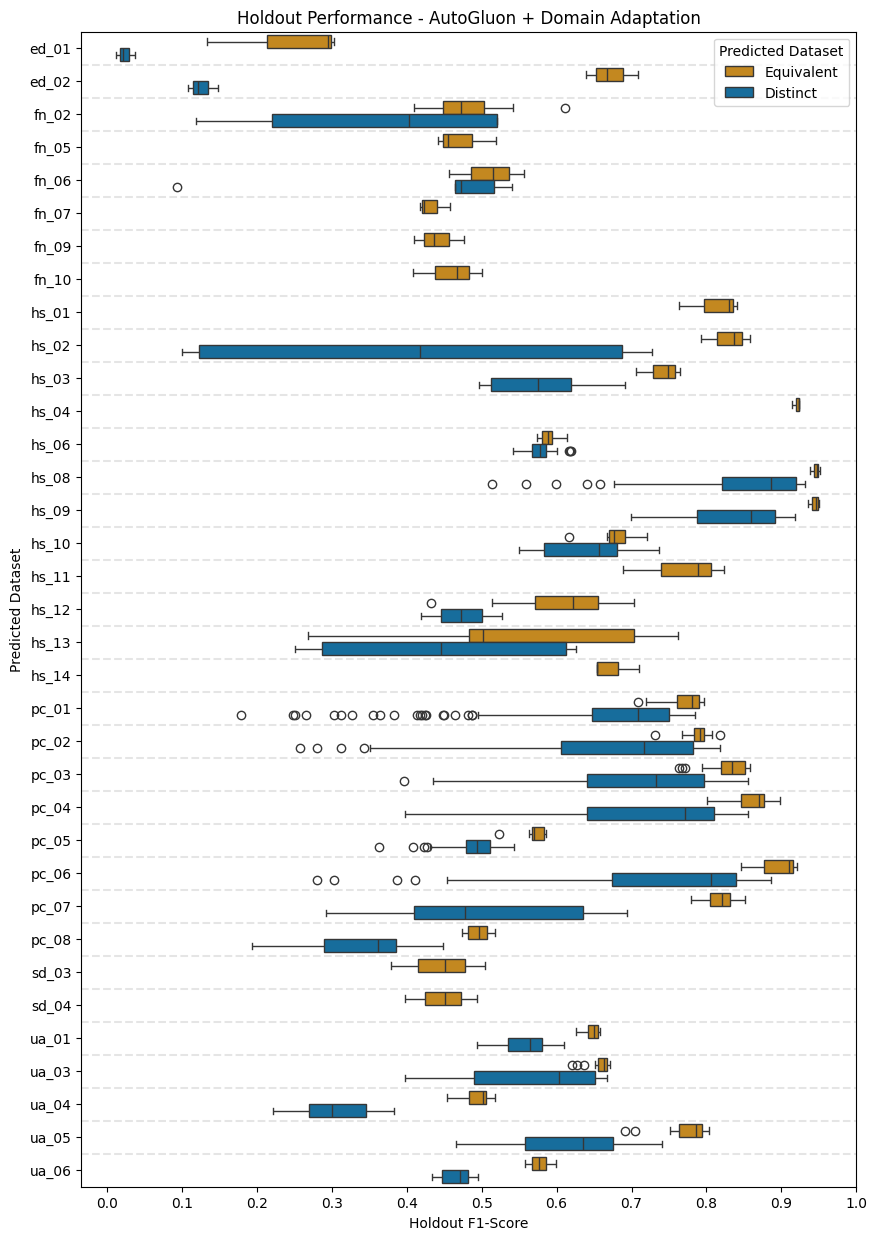

In [8]:
fig, ax = plt.subplots(figsize=(10, 15))

automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_ag.csv",
    sep=";"
)

adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["predicted_dataset"]
aug_mask = automl_concat_df["trained_dataset"] == automl_concat_df["predicted_dataset"]

automl_concat_df.loc[adapt_mask & (~aug_mask), "Predicted Dataset"] = "Equivalent"
automl_concat_df.loc[(~adapt_mask) & (~aug_mask), "Predicted Dataset"] = "Distinct"

# Filter out datasets with no data points
automl_concat_df = automl_concat_df.dropna(subset=["Predicted Dataset"])

# Get the unique values of predicted_dataset in the desired order
dataset_order = sorted(automl_concat_df["predicted_dataset"].unique())

automl_concat_df["predicted_dataset"] = pd.Categorical(
    automl_concat_df["predicted_dataset"],
    categories=dataset_order,
    ordered=True
)

automl_concat_df = automl_concat_df.sort_values(by="predicted_dataset")
print(len(automl_concat_df))

ax = sns.boxplot(
    data=automl_concat_df,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="Predicted Dataset",
    palette=dict(zip(["Distinct", "Equivalent"], sns.color_palette("colorblind")))
)

# There are 43 datasets, we create a horizontal line to separate them
num_hlines = len(automl_concat_df["predicted_dataset"].unique()) - 1 # Do not draw last
for i in range(num_hlines):
    ax.axhline(y=i + .5, color='black', linestyle='--', alpha=.1)

ax.set_title("Holdout Performance - AutoGluon + Domain Adaptation")
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xticks(np.arange(0, 1.1, 0.1))
plt.savefig("holdout_performance_autogluon_domain_adaptation.pdf", format="pdf", bbox_inches="tight")

In [9]:
len(automl_concat_df["predicted_dataset"].unique()) - 1

34

1662


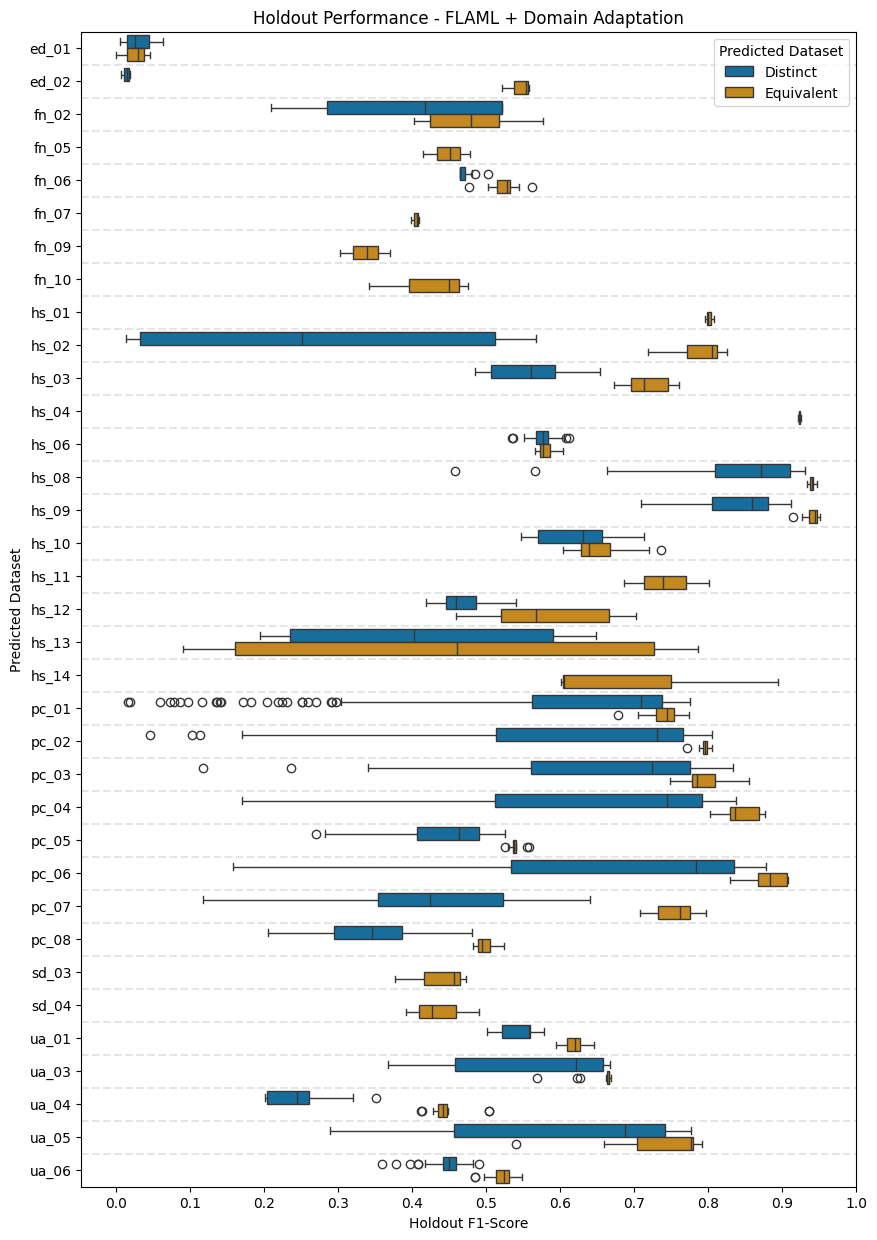

In [10]:
fig, ax = plt.subplots(figsize=(10, 15))

automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_flaml.csv",
    sep=";"
)

adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["predicted_dataset"]
aug_mask = automl_concat_df["trained_dataset"] == automl_concat_df["predicted_dataset"]

automl_concat_df.loc[adapt_mask & (~aug_mask), "Predicted Dataset"] = "Equivalent"
automl_concat_df.loc[(~adapt_mask) & (~aug_mask), "Predicted Dataset"] = "Distinct"

# Filter out datasets with no data points
automl_concat_df = automl_concat_df.dropna(subset=["Predicted Dataset"])

# Get the unique values of predicted_dataset in the desired order
dataset_order = sorted(automl_concat_df["predicted_dataset"].unique())

automl_concat_df["predicted_dataset"] = pd.Categorical(
    automl_concat_df["predicted_dataset"],
    categories=dataset_order,
    ordered=True
)

automl_concat_df = automl_concat_df.sort_values(by="predicted_dataset")
print(len(automl_concat_df))

ax = sns.boxplot(
    data=automl_concat_df,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="Predicted Dataset",
    palette=dict(zip(["Distinct", "Equivalent"], sns.color_palette("colorblind")))
)

# There are 43 datasets, we create a horizontal line to separate them
num_hlines = len(automl_concat_df["predicted_dataset"].unique()) - 1 # Do not draw last
for i in range(num_hlines):
    ax.axhline(y=i + .5, color='black', linestyle='--', alpha=.1)

ax.set_title("Holdout Performance - FLAML + Domain Adaptation")
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xticks(np.arange(0, 1.1, 0.1))
plt.savefig("holdout_performance_flaml_domain_adaptation.pdf", format="pdf", bbox_inches="tight")

1662


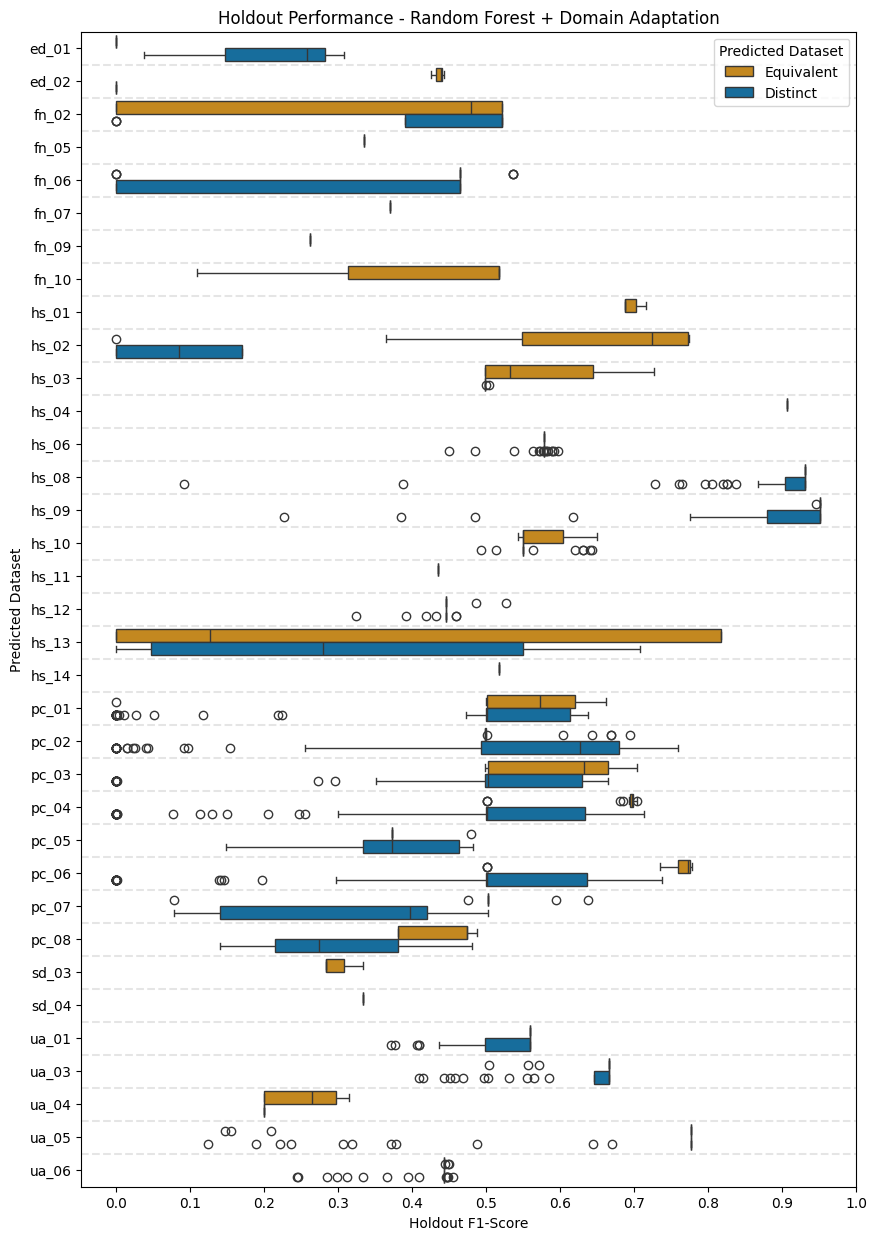

In [11]:
fig, ax = plt.subplots(figsize=(10, 15))

automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_rf.csv",
    sep=";"
)
adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["predicted_dataset"]
aug_mask = automl_concat_df["trained_dataset"] == automl_concat_df["predicted_dataset"]

automl_concat_df.loc[adapt_mask & (~aug_mask), "Predicted Dataset"] = "Equivalent"
automl_concat_df.loc[(~adapt_mask) & (~aug_mask), "Predicted Dataset"] = "Distinct"

# Filter out datasets with no data points
automl_concat_df = automl_concat_df.dropna(subset=["Predicted Dataset"])

# Get the unique values of predicted_dataset in the desired order
dataset_order = sorted(automl_concat_df["predicted_dataset"].unique())

automl_concat_df["predicted_dataset"] = pd.Categorical(
    automl_concat_df["predicted_dataset"],
    categories=dataset_order,
    ordered=True
)

automl_concat_df = automl_concat_df.sort_values(by="predicted_dataset")
print(len(automl_concat_df))

ax = sns.boxplot(
    data=automl_concat_df,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="Predicted Dataset",
    palette=dict(zip(["Distinct", "Equivalent"], sns.color_palette("colorblind")))
)

# There are 43 datasets, we create a horizontal line to separate them
num_hlines = len(automl_concat_df["predicted_dataset"].unique()) - 1 # Do not draw last
for i in range(num_hlines):
    ax.axhline(y=i + .5, color='black', linestyle='--', alpha=.1)

ax.set_title("Holdout Performance - Random Forest + Domain Adaptation")
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xticks(np.arange(0, 1.1, 0.1))
plt.savefig("holdout_performance_rf_domain_adaptation.pdf", format="pdf", bbox_inches="tight")

In [12]:
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

hpo = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)

In [13]:
hpo.columns

Index(['trained_dataset', 'predicted_dataset', 'automl_system', 'method',
       'percentage', 'missing_in_pred', 'extra_in_pred',
       'only_one_predicted_label', 'f1_micro_majority', 'hold_out_f1_score',
       'y_true_labels', 'y_pred_labels'],
      dtype='object')

In [14]:
hpo[hpo["percentage"]==100]

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels
0,pc_02,pc_01,FLAML,gmm_random,100,[],[],False,0.501181,0.706188,"['negative', 'positive']","['negative', 'positive']"
1,pc_02,pc_03,FLAML,gmm_random,100,[],[],False,0.501573,0.731290,"['negative', 'positive']","['negative', 'positive']"
2,pc_02,pc_04,FLAML,gmm_random,100,[],[],False,0.500481,0.777217,"['negative', 'positive']","['negative', 'positive']"
3,pc_02,pc_06,FLAML,gmm_random,100,[],[],False,0.500622,0.825439,"['negative', 'positive']","['negative', 'positive']"
4,pc_02,pc_02,FLAML,gmm_random,100,[],[],False,0.501416,0.796034,"['negative', 'positive']","['negative', 'positive']"
...,...,...,...,...,...,...,...,...,...,...,...,...
517,pc_08,pc_06,Random Forest with Random Search,gmm_random,100,['negative'],[],True,0.500622,0.499378,"['negative', 'positive']",['positive']
518,pc_08,pc_07,Random Forest with Random Search,gmm_random,100,"['negative', 'neutral']",[],True,0.502058,0.078189,"['positive', 'negative', 'neutral']",['positive']
519,pc_08,pc_08,Random Forest with Random Search,gmm_random,100,"['neutral', 'negative']",[],True,0.479628,0.479628,"['neutral', 'negative', 'positive']",['positive']
520,hs_02,hs_13,Random Forest with Random Search,gmm_random,100,"['neither', 'hate']",[],True,0.816537,0.126615,"['hate', 'offensive', 'neither']",['offensive']


49


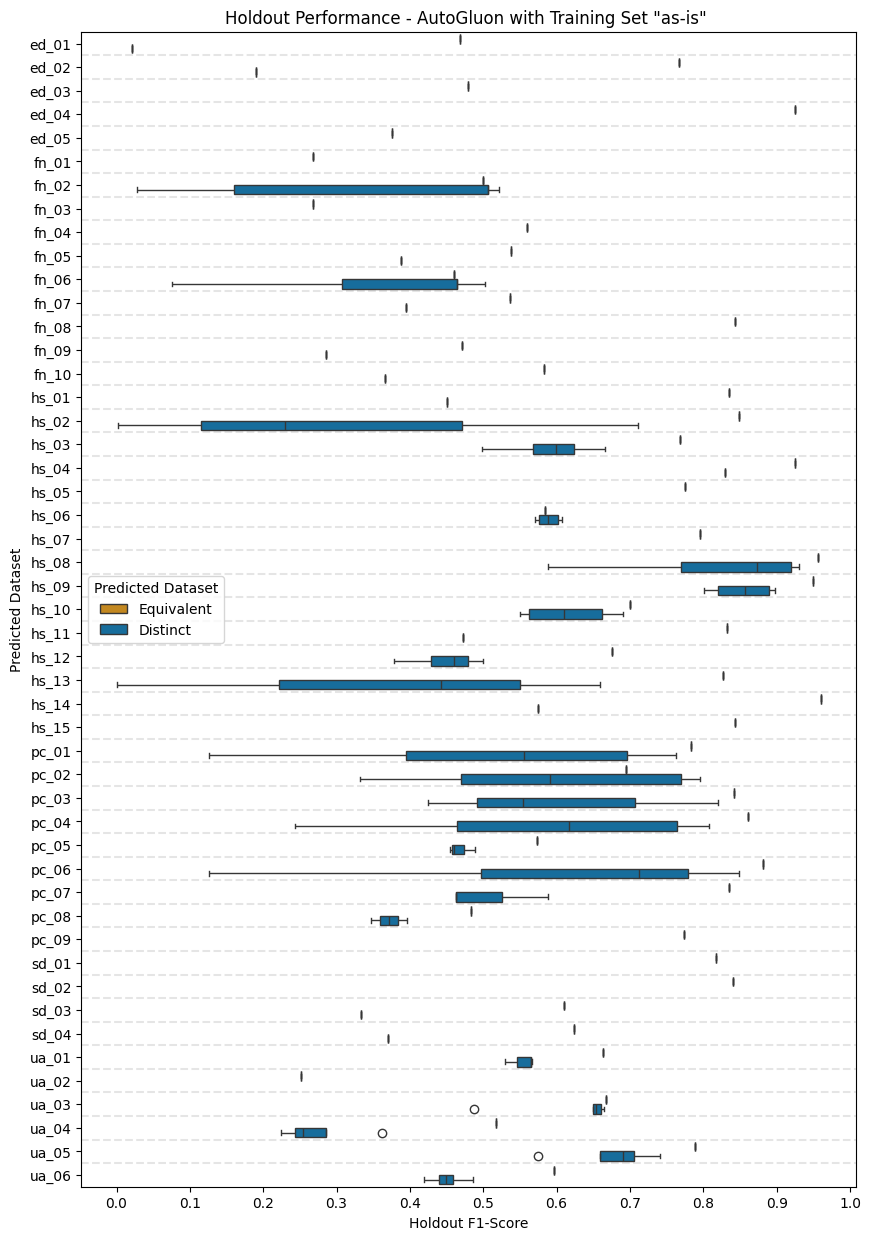

In [15]:
system = "ag"

fig, ax = plt.subplots(figsize=(10, 15))

df = hpo[hpo["automl_system"] == system_map[system]].copy()

df["Predicted Dataset"] = df.apply(
    lambda row: "Equivalent" if row["trained_dataset"] == row["predicted_dataset"] else "Distinct",
    axis=1
)
df = df.sort_values(by="predicted_dataset")

ax = sns.boxplot(
    data=df,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="Predicted Dataset",
    palette=dict(zip(["Distinct", "Equivalent"], sns.color_palette("colorblind")))
)
print(len(df["predicted_dataset"].unique()))
# There are 43 datasets, we create a horizontal line to separate them
num_hlines = len(df["predicted_dataset"].unique()) - 1 # Do not draw last
for i in range(num_hlines):
    ax.axhline(y=i + .5, color='black', linestyle='--', alpha=.1)

ax.set_title("""Holdout Performance - AutoGluon with Training Set "as-is" """)
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xticks(np.arange(0, 1.1, 0.1))
plt.savefig("holdout_performance_autogluon_hpo.pdf", format="pdf", bbox_inches="tight")

49


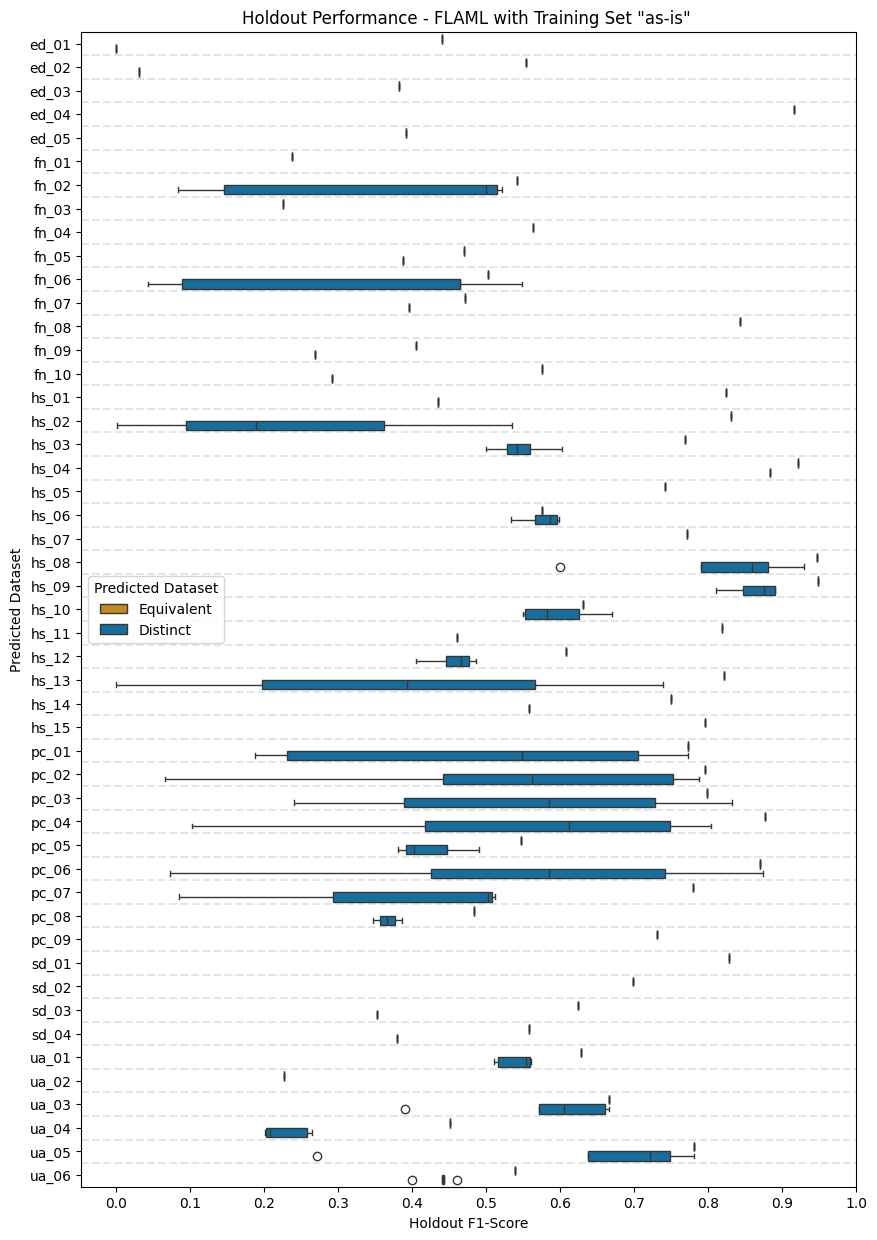

In [16]:
system = "flaml"

fig, ax = plt.subplots(figsize=(10, 15))

df = hpo[hpo["automl_system"] == system_map[system]].copy()

df["Predicted Dataset"] = df.apply(
    lambda row: "Equivalent" if row["trained_dataset"] == row["predicted_dataset"] else "Distinct",
    axis=1
)
df = df.sort_values(by="predicted_dataset")

ax = sns.boxplot(
    data=df,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="Predicted Dataset",
    palette=dict(zip(["Distinct", "Equivalent"], sns.color_palette("colorblind")))
)
print(len(df["predicted_dataset"].unique()))
# There are 43 datasets, we create a horizontal line to separate them
num_hlines = len(df["predicted_dataset"].unique()) - 1 # Do not draw last
for i in range(num_hlines):
    ax.axhline(y=i + .5, color='black', linestyle='--', alpha=.1)

ax.set_title("""Holdout Performance - FLAML with Training Set "as-is" """)
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xticks(np.arange(0, 1.1, 0.1))
plt.savefig("holdout_performance_flaml_hpo.pdf", format="pdf", bbox_inches="tight")

In [17]:
system = "rf"

# fig, ax = plt.subplots(figsize=(10, 15))

df = hpo[hpo["automl_system"] == system_map[system]].copy()
df

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels
347,sd_01,sd_01,Random Forest with Random Search,gmm_random,100,[],[],False,0.687500,0.807292,"['hyperpartisan', 'not_hyperpartisan']","['hyperpartisan', 'not_hyperpartisan']"
348,fn_03,fn_02,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.520833,0.000000,"['false', 'true']",['half_true']
349,fn_03,fn_06,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.535865,0.000000,"['false', 'true']",['half_true']
350,fn_03,fn_03,Random Forest with Random Search,gmm_random,100,"['pants_on_fire', 'mostly_false', 'full_flop',...",[],True,0.198683,0.198683,"['pants_on_fire', 'mostly_false', 'full_flop',...",['half_true']
351,fn_09,fn_10,Random Forest with Random Search,gmm_random,100,"['false', 'true', 'no_opinion']",[],True,0.516667,0.108333,"['out_of_scope', 'false', 'true', 'no_opinion']",['out_of_scope']
...,...,...,...,...,...,...,...,...,...,...,...,...
517,pc_08,pc_06,Random Forest with Random Search,gmm_random,100,['negative'],[],True,0.500622,0.499378,"['negative', 'positive']",['positive']
518,pc_08,pc_07,Random Forest with Random Search,gmm_random,100,"['negative', 'neutral']",[],True,0.502058,0.078189,"['positive', 'negative', 'neutral']",['positive']
519,pc_08,pc_08,Random Forest with Random Search,gmm_random,100,"['neutral', 'negative']",[],True,0.479628,0.479628,"['neutral', 'negative', 'positive']",['positive']
520,hs_02,hs_13,Random Forest with Random Search,gmm_random,100,"['neither', 'hate']",[],True,0.816537,0.126615,"['hate', 'offensive', 'neither']",['offensive']


In [18]:
len(df["predicted_dataset"].unique())

49

49


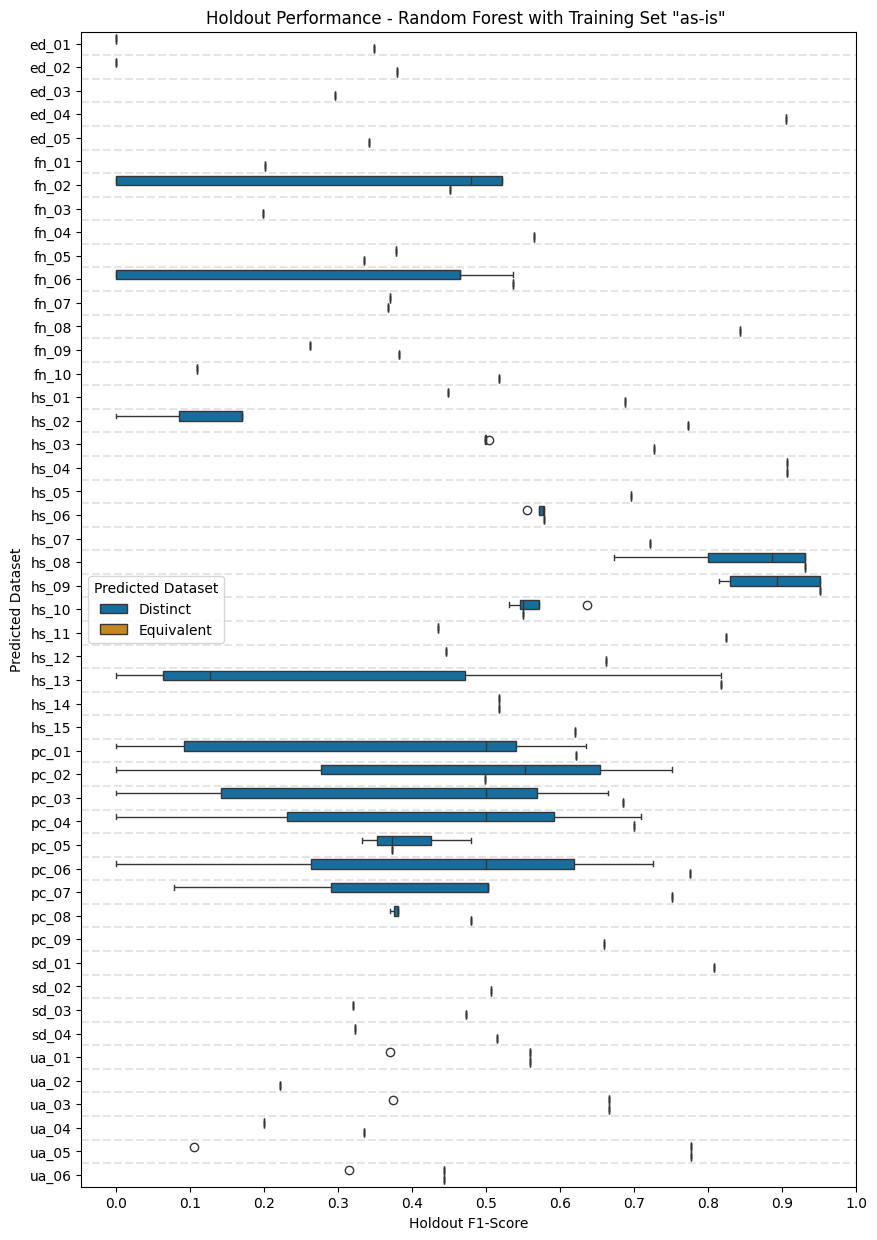

In [19]:
system = "rf"

fig, ax = plt.subplots(figsize=(10, 15))

df = hpo[hpo["automl_system"] == system_map[system]].copy()

df["percentage"] = 100

df = df.drop_duplicates(subset=["trained_dataset","predicted_dataset"])

df["Predicted Dataset"] = df.apply(
    lambda row: "Equivalent" if row["trained_dataset"] == row["predicted_dataset"] else "Distinct",
    axis=1
)
df = df.sort_values(by="predicted_dataset")

ax = sns.boxplot(
    data=df,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="Predicted Dataset",
    palette=dict(zip(["Distinct", "Equivalent"], sns.color_palette("colorblind")))
)
print(len(df["predicted_dataset"].unique()))
# There are 43 datasets, we create a horizontal line to separate them
num_hlines = len(df["predicted_dataset"].unique()) - 1 # Do not draw last
for i in range(num_hlines):
    ax.axhline(y=i + .5, color='black', linestyle='--', alpha=.1)

ax.set_title("""Holdout Performance - Random Forest with Training Set "as-is" """)
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xticks(np.arange(0, 1.1, 0.1))
plt.savefig("holdout_performance_rf_hpo.pdf", format="pdf", bbox_inches="tight")

In [20]:
len(df["trained_dataset"].unique())

49

# LLMs

## LLama

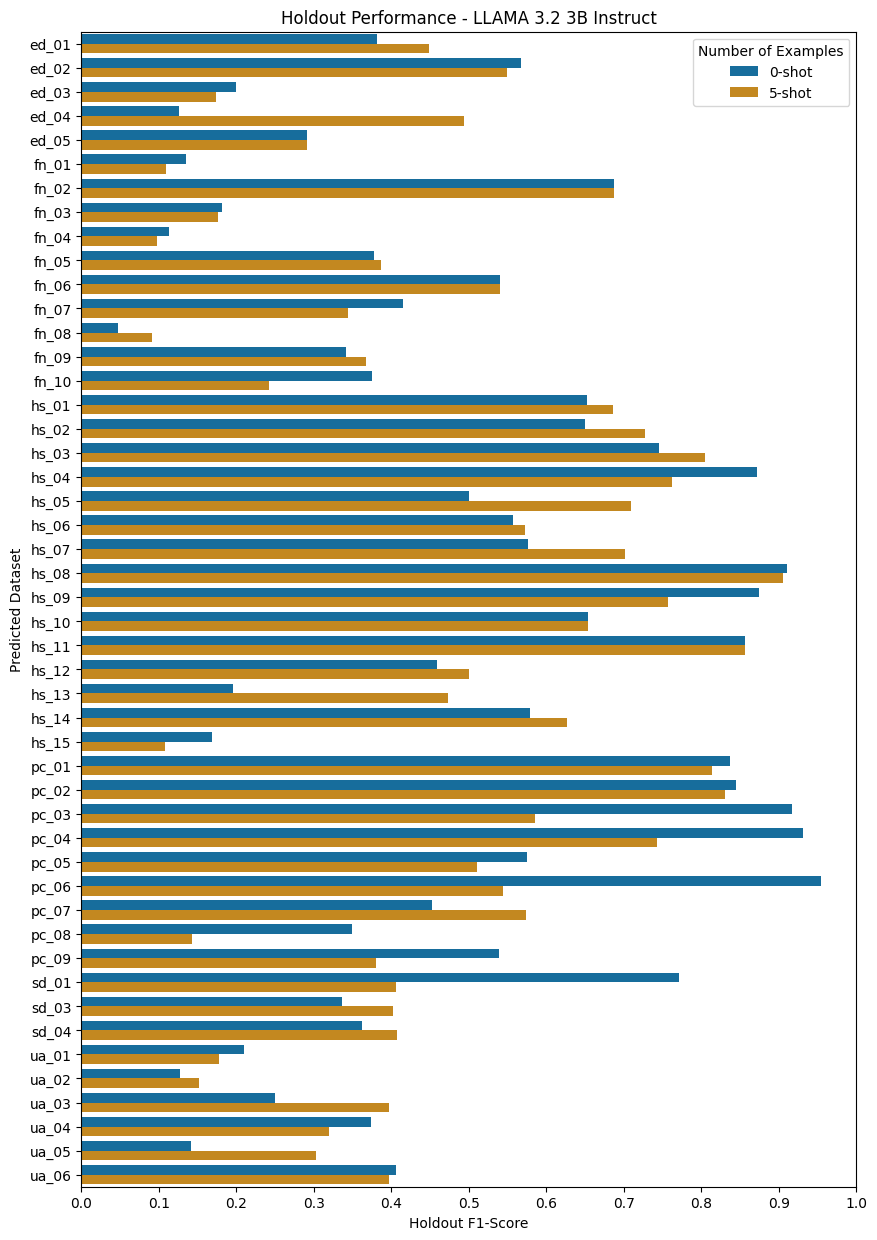

In [21]:
llama = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/llama.csv",
    sep=";"
)
fig, ax = plt.subplots(figsize=(10, 15))

sns.barplot(
    data=llama,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="number_of_examples",
    palette=dict(zip([0, 5], sns.color_palette("colorblind"))),
    ax=ax
)

ax.set_title("Holdout Performance - LLAMA 3.2 3B Instruct")
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xlim([0, 1])

# Modify legend title and labels
handles, labels = ax.get_legend_handles_labels()
ax.set_xticks(np.arange(0, 1.1, 0.1))
ax.legend(handles=handles, labels=["0-shot", "5-shot"], title="Number of Examples")
plt.savefig("holdout_performance_llama.pdf", format="pdf", bbox_inches="tight")
plt.show()


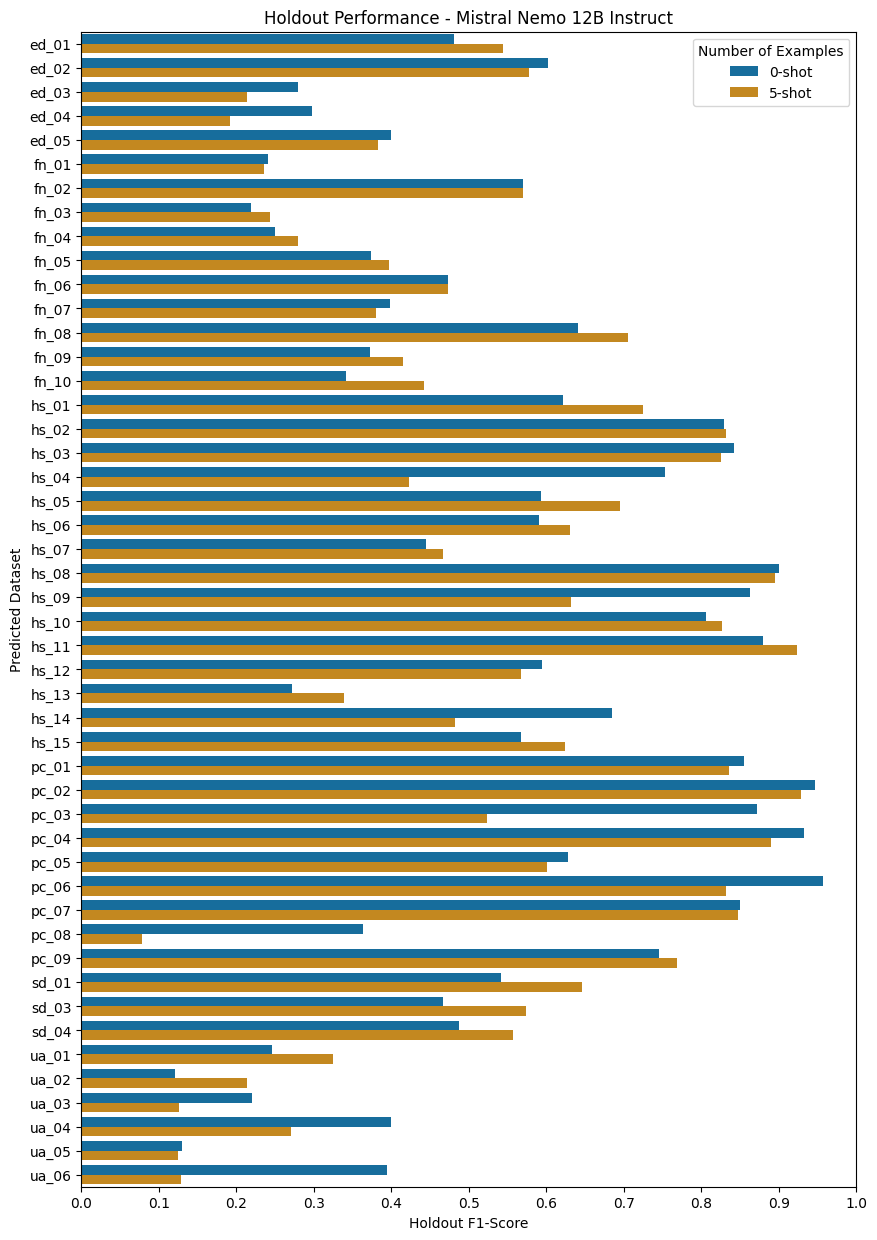

In [22]:
mistral = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/mistral.csv",
    sep=";"
)
fig, ax = plt.subplots(figsize=(10, 15))

sns.barplot(
    data=mistral,
    x="hold_out_f1_score",
    y="predicted_dataset",
    hue="number_of_examples",
    palette=dict(zip([0, 5], sns.color_palette("colorblind"))),
    ax=ax
)

ax.set_title("Holdout Performance - Mistral Nemo 12B Instruct")
ax.set_xlabel("Holdout F1-Score")
ax.set_ylabel("Predicted Dataset")
ax.set_xlim([0, 1])

# Modify legend title and labels
handles, labels = ax.get_legend_handles_labels()
ax.set_xticks(np.arange(0, 1.1, 0.1))
ax.legend(handles=handles, labels=["0-shot", "5-shot"], title="Number of Examples")
plt.savefig("holdout_performance_mistral.pdf", format="pdf", bbox_inches="tight")
plt.show()
